<a href="https://colab.research.google.com/github/SPRIYANS2006/Image-Processing-Assignments/blob/main/Assign11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Setup: Download and Prepare Tiny ImageNet
We will download the Tiny ImageNet dataset, extract it, and select 3 random classes with 200 images each to build our 600-image dataset (split into 70% Train, 15% Val, 15% Test).

In [1]:
import os
import shutil
import urllib.request
import zipfile
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

# Download Tiny ImageNet
url = 'http://cs231n.stanford.edu/tiny-imagenet-200.zip'
zip_path = 'tiny-imagenet-200.zip'
extract_path = 'tiny-imagenet-200'

if not os.path.exists(zip_path):
    print("Downloading Tiny ImageNet...")
    urllib.request.urlretrieve(url, zip_path)

if not os.path.exists(extract_path):
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('.')

print("Dataset downloaded and extracted successfully!")

Extracting dataset...
Dataset downloaded and extracted successfully!


In [6]:
# Select 3 classes and prepare 600 images total (200 images per class)
import os
import numpy as np
from PIL import Image

np.random.seed(42)
train_dir = os.path.join(extract_path, 'tiny-imagenet-200', 'train')
if not os.path.exists(train_dir):
    # Fallback to direct path in case it is at root level
    train_dir = os.path.join(extract_path, 'train')

all_classes = os.listdir(train_dir)
selected_classes = np.random.choice(all_classes, 3, replace=False)
print(f"Selected Classes: {selected_classes}")

X = []
y = []

for label_idx, class_name in enumerate(selected_classes):
    class_path = os.path.join(train_dir, class_name, 'images')
    images = os.listdir(class_path)[:200]  # Take 200 images
    for img_name in images:
        img_path = os.path.join(class_path, img_name)
        try:
            with Image.open(img_path) as img:
                img_arr = np.array(img.convert('RGB'))
                X.append(img_arr)
                y.append(label_idx)
        except Exception as e:
            print(f"Error loading image {img_path}: {e}")

X = np.array(X) / 255.0  # Normalize to [0, 1]
y = np.array(y)

print(f"Data Shape: {X.shape}")
print(f"Labels Shape: {y.shape}")

Selected Classes: ['n07768694' 'n02883205' 'n02788148']
Data Shape: (600, 64, 64, 3)
Labels Shape: (600,)


In [10]:
# Split data into Train (70%), Validation (15%), and Test (15%)
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print(f"Train size: {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Val size: {X_val.shape[0]} ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"Test size: {X_test.shape[0]} ({X_test.shape[0]/len(X)*100:.1f}%)")

Train size: 420 (70.0%)
Val size: 90 (15.0%)
Test size: 90 (15.0%)


### Task 1: CNN Basics on a 3x3 Matrix
Let's implement NumPy operations for Convolution, Padding, Activation Functions, Pooling operations, and other core NN concepts.

In [4]:
import numpy as np

# Initialize a random 3x3 matrix
np.random.seed(42)
matrix = np.random.rand(3, 3)
print("Original 3x3 Matrix:\n", matrix)

# 1. Padding (P=1)
padded_matrix = np.pad(matrix, pad_width=1, mode='constant', constant_values=0)
print("\nPadded Matrix (P=1):\n", padded_matrix)

# 2. Convolution (using a 3x3 kernel on the padded matrix to get a 3x3 output)
kernel = np.array([
    [0, 1, 0],
    [1, -4, 1],
    [0, 1, 0]
])

conv_output = np.zeros((3, 3))
for i in range(3):
    for j in range(3):
        region = padded_matrix[i:i+3, j:j+3]
        conv_output[i, j] = np.sum(region * kernel)
print("\nConvolution Output (with 3x3 Laplace Kernel):\n", conv_output)

# 3. Activation Functions (ReLU and Sigmoid)
def relu(x):
    return np.maximum(0, x)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

print("\nReLU Activation:\n", relu(conv_output))
print("\nSigmoid Activation:\n", sigmoid(conv_output))

Original 3x3 Matrix:
 [[0.37454012 0.95071431 0.73199394]
 [0.59865848 0.15601864 0.15599452]
 [0.05808361 0.86617615 0.60111501]]

Padded Matrix (P=1):
 [[0.         0.         0.         0.         0.        ]
 [0.         0.37454012 0.95071431 0.73199394 0.        ]
 [0.         0.59865848 0.15601864 0.15599452 0.        ]
 [0.         0.05808361 0.86617615 0.60111501 0.        ]
 [0.         0.         0.         0.         0.        ]]

Convolution Output (with 3x3 Laplace Kernel):
 [[ 0.05121232 -2.54030452 -1.82126694]
 [-1.80599157  1.94746889  0.86514951]
 [ 1.23250018 -2.64948732 -1.38228938]]

ReLU Activation:
 [[0.05121232 0.         0.        ]
 [0.         1.94746889 0.86514951]
 [1.23250018 0.         0.        ]]

Sigmoid Activation:
 [[0.51280028 0.07308054 0.13928192]
 [0.14112328 0.87517039 0.70373541]
 [0.77425586 0.06602062 0.20064157]]


In [5]:
# 4. Pooling operations
# For demonstration, we will use a 2x2 patch from the top-left of the padded matrix
pool_region = padded_matrix[0:2, 0:2]
print("2x2 Pool Region Sample:\n", pool_region)

max_pooling = np.max(pool_region)
min_pooling = np.min(pool_region)
global_average_pooling = np.mean(padded_matrix)

print(f"\nMax Pooling (2x2): {max_pooling}")
print(f"Min Pooling (2x2): {min_pooling}")
print(f"Global Average Pooling (over entire padded matrix): {global_average_pooling}")

2x2 Pool Region Sample:
 [[0.         0.        ]
 [0.         0.37454012]]

Max Pooling (2x2): 0.3745401188473625
Min Pooling (2x2): 0.0
Global Average Pooling (over entire padded matrix): 0.17973179126922811


### Task 1 (Continued): Flattening, Dense, Batch Normalization, Dropout, and Early Stopping
Let's write a simple program demonstrating these operations.

In [7]:
import numpy as np

# 5. Flattening
mock_conv_output = np.random.rand(2, 2, 3) # (Height, Width, Channels)
flattened = mock_conv_output.flatten()
print("Mock Conv Output (2x2x3) Shape:", mock_conv_output.shape)
print("Flattened Shape:", flattened.shape)

# 6. Dense (Fully Connected) Layer
np.random.seed(42)
weights = np.random.rand(len(flattened), 5) # Dense layer with 5 outputs
biases = np.zeros(5)
dense_output = np.dot(flattened, weights) + biases
print("\nDense Layer Output (5 units):\n", dense_output)

# 7. Batch Normalization (on dense output)
mean = np.mean(dense_output)
variance = np.var(dense_output)
epsilon = 1e-5
gamma, beta = 1.0, 0.0
bn_output = gamma * ((dense_output - mean) / np.sqrt(variance + epsilon)) + beta
print("\nBatch Normalization Output:\n", bn_output)

# 8. Dropout (Keep probability = 0.5)
keep_prob = 0.5
dropout_mask = (np.random.rand(*bn_output.shape) < keep_prob) / keep_prob
dropout_output = bn_output * dropout_mask
print("\nDropout Output (applied to BN):\n", dropout_output)

# 9. Early Stopping Simulation
validation_losses = [1.2, 1.0, 0.8, 0.7, 0.75, 0.78, 0.82]
patience = 2
best_loss = float('inf')
patience_counter = 0

print("\nSimulating Early Stopping:")
for epoch, loss in enumerate(validation_losses):
    print(f"Epoch {epoch+1}: Val Loss = {loss}")
    if loss < best_loss:
        best_loss = loss
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping triggered at Epoch {epoch+1}!")
            break

Mock Conv Output (2x2x3) Shape: (2, 2, 3)
Flattened Shape: (12,)

Dense Layer Output (5 units):
 [3.16349024 2.40242938 2.64916178 3.59005319 2.33826948]

Batch Normalization Output:
 [ 0.69926515 -0.89024607 -0.37493391  1.59016184 -1.02424702]

Dropout Output (applied to BN):
 [ 1.39853031 -1.78049214 -0.          3.18032368 -2.04849404]

Simulating Early Stopping:
Epoch 1: Val Loss = 1.2
Epoch 2: Val Loss = 1.0
Epoch 3: Val Loss = 0.8
Epoch 4: Val Loss = 0.7
Epoch 5: Val Loss = 0.75
Epoch 6: Val Loss = 0.78
Early stopping triggered at Epoch 6!


### Task 2: Custom CNN and Overfitting Analysis
We will define a custom CNN using Keras, train it on our 3-class Tiny ImageNet dataset subset, and plot training/validation loss curves to observe overfitting.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/25
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 321ms/step - accuracy: 0.5000 - loss: 4.6308 - val_accuracy: 0.4222 - val_loss: 1.5551
Epoch 2/25
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 287ms/step - accuracy: 0.5952 - loss: 1.7627 - val_accuracy: 0.3778 - val_loss: 1.3714
Epoch 3/25
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 412ms/step - accuracy: 0.6333 - loss: 0.9367 - val_accuracy: 0.3556 - val_loss: 1.3928
Epoch 4/25
14/14 ━━━━━━━━━━━━━━━━━━━━ 9s 357ms/step - accuracy: 0.7214 - loss: 0.7300 - val_accuracy: 0.3778 - val_loss: 1.4489
Epoch 5/25
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 350ms/step - accuracy: 0.7476 - loss: 0.6462 - val_accuracy: 0.4111 - val_loss: 1.5009
Epoch 6/25
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 299ms/step - accuracy: 0.7762 - loss: 0.5689 - val_accuracy: 0.3889 - val_loss: 1.7048
Epoch 7/25
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 352ms/step - accuracy: 0.8405 - loss: 0.3810 - val_accuracy: 0.3778 - val_loss: 1.9369
Epoch 8/25
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 349ms/step - accuracy: 0.8214 - loss: 0.4631 - val_accuracy: 0.

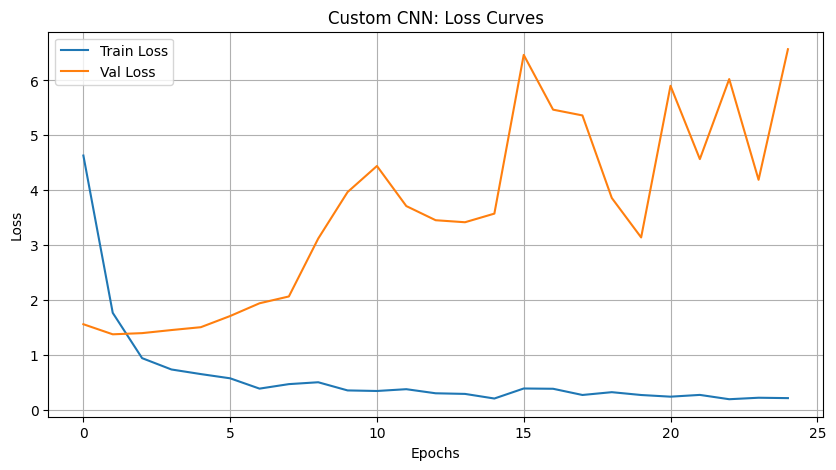

In [11]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

def build_custom_cnn():
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(64, 64, 3)),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(3, activation='softmax')
    ])
    return model

custom_model = build_custom_cnn()
custom_model.compile(optimizer='adam',
                     loss='sparse_categorical_crossentropy',
                     metrics=['accuracy'])

# Train the model
history = custom_model.fit(
    X_train, y_train,
    epochs=25,
    validation_data=(X_val, y_val),
    batch_size=32
)

# Plot loss curves
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Custom CNN: Loss Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

### Task 3: Transfer Learning Comparison
Now we will train VGG16, MobileNet, and ResNet50 (using pre-trained weights) on the same dataset, then evaluate test accuracy, precision, recall, and F1-score.

In [12]:
from sklearn.metrics import classification_report, accuracy_score, precision_recall_fscore_support
import pandas as pd

def train_and_evaluate_transfer_model(model_name, base_model_fn):
    print(f"\nTraining {model_name}...")
    # Resize/preprocess images if needed, or build directly
    base_model = base_model_fn(weights='imagenet', include_top=False, input_shape=(64, 64, 3))
    base_model.trainable = False  # Freeze base weights

    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(3, activation='softmax')
    ])

    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    model.fit(X_train, y_train, epochs=15, validation_data=(X_val, y_val), batch_size=32, verbose=0)

    # Predict on test data
    preds = np.argmax(model.predict(X_test), axis=1)

    # Calculate metrics
    acc = accuracy_score(y_test, preds)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, preds, average='macro')

    return {'Model': model_name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1}

results = []

# Evaluate Custom CNN on Test Set
custom_preds = np.argmax(custom_model.predict(X_test), axis=1)
custom_acc = accuracy_score(y_test, custom_preds)
custom_prec, custom_rec, custom_f1, _ = precision_recall_fscore_support(y_test, custom_preds, average='macro')
results.append({'Model': 'Custom CNN', 'Accuracy': custom_acc, 'Precision': custom_prec, 'Recall': custom_rec, 'F1-Score': custom_f1})

# Evaluate pre-trained architectures
from tensorflow.keras.applications import VGG16, MobileNetV2, ResNet50

results.append(train_and_evaluate_transfer_model('VGG16', VGG16))
results.append(train_and_evaluate_transfer_model('MobileNetV2', MobileNetV2))
results.append(train_and_evaluate_transfer_model('ResNet50', ResNet50))

# Compare all results in a DataFrame
comparison_df = pd.DataFrame(results)
print("\n--- Comparison Table ---")
print(comparison_df.to_string(index=False))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step

Training VGG16...
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step

Training MobileNetV2...


/tmp/ipykernel_784/3880738389.py:7: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = base_model_fn(weights='imagenet', include_top=False, input_shape=(64, 64, 3))


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 919ms/step

Training ResNet50...
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step

--- Comparison Table ---
      Model  Accuracy  Precision   Recall  F1-Score
 Custom CNN  0.466667   0.576144 0.466667  0.419841
      VGG16  0.888889   0.892565 0.888889  0.885852
MobileNetV2  0.922222   0.921431 0.922222  0.921654
   ResNet50  0.577778   0.619328 0.577778  0.562920
